# SARS-CoV-2 Surface Glycoprotein Sequences

1. 資料處理（Data processing）
步驟	做法	工具
擷取 spike	從全基因體切出 S 基因（Wuhan-Hu-1 的 21563–25384），或直接用 NCBI 的蛋白序列	Biopython、nextclade
品質過濾	去掉含大量 N、長度異常、含終止密碼子的序列；data_report.jsonl 裡有 collection date、host、location，可一起過濾	pandas
去重	完全相同的序列合併，只保留計數與最早出現日期（論文通常靠這步把數百萬條壓到幾萬個唯一序列）	seqkit rmdup、cd-hit
多序列比對（MSA）	對齊到參考序列，固定長度 1273 aa	mafft --keeplength --addfragments、nextclade
編碼	one-hot（L×21，含 gap），或 embedding	numpy
時間切分	依採集日期切成訓練集與未來測試集，不要隨機切	pandas
NCBI 的 genomic.fna 一般不含 pango lineage。要標 lineage 可用 pangolin，或用 Nextclade 的 clade 輸出。

2. 資料探勘（Data mining）
突變頻率與時間趨勢：每個位點在每個月的突變頻率，找出快速上升的突變。
共現突變：突變之間的關聯，可用互資訊或 Direct Coupling Analysis（DCA）。
系統發生樹：IQ-TREE 或 UShER，再用 Nextstrain/Auspice 檢視。
序列聚類：k-mer 或 Hamming 距離，再做 UMAP。

In [9]:
from pathlib import Path
from Bio import SeqIO
from itertools import islice

# Notebook is under Research/FE/; walk up until repo root is found
repo = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data/spike-protein/sequences.fasta").exists()
)
path = repo / "data/spike-protein/sequences.fasta"
print("Reading:", path)

for record in islice(SeqIO.parse(path, "fasta"), 3):
    print(record.id)
    print(len(record.seq))          # Spike AA length (1273)
    print(record.description)
    print(str(record.seq)[:100])    # amino acids, not DNA




Reading: /home/cliffyang/Project/SARS-CoV-2-Quantum/data/spike-protein/sequences.fasta
YP_009724390.1
1273
YP_009724390.1 |China|2019-12
MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSSVLHSTQDLFLPFFSNVTWFHAIHVSGTNGTKRFDNPVLPFNDGVYFASTEKSNI
UCN23696.1
1273
UCN23696.1 |Kenya|2020-04-20
MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSSVLHSTQDLFLPFFSNVTWFHAIHVSGTNGTKRFDNPVLPFNDGVYFASTEKSNI
UCN23812.1
1273
UCN23812.1 |Kenya|2020-06-08
MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSSVLHSTQDLFLPFFSNVTWFHAIHVSGTNGTKRFDNPVLPFNDGVYFASTEKSNI


In [10]:
# from pymol import cmd

# cmd.fetch("6VXX")
# cmd.hide("everything")
# cmd.show("cartoon")
# cmd.png("spike.png", dpi=300, ray=1)

## 0. 資料說明與流程調整
- 這份 spike 資料（NCBI Virus，快照 2021-10-12）**已經是 1273 aa 等長**，且沒有 indel，因此：
  - 不需要從全基因體切 S 基因（那是 `data/sars_ba1` 的流程）。
  - **不需要再做 MSA**：位置 i 直接對應 Wuhan-Hu-1（`YP_009724390.1`）的第 i 個殘基。
- 序列 header 只有 `Accession |Country|Date`，沒有 lineage。這裡用**關鍵突變**（D614G、N501Y、E484K、L452R…）當作 lineage 的代理標籤。
- 時間範圍 2019-12 ~ 2021-10，涵蓋 D614G → Alpha → Delta，足以做時間切分。

In [11]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import sparse
from Bio import SeqIO

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
REF_ID = "YP_009724390.1"     # Wuhan-Hu-1 spike
L = 1273

rows = []
for r in SeqIO.parse(path, "fasta"):          # `path` 來自上面的讀檔 cell
    _, country, date = [p.strip() for p in r.description.split("|")][:3]
    rows.append((r.id, country, date, str(r.seq)))
df = pd.DataFrame(rows, columns=["acc", "country", "date_raw", "seq"])
df["date"] = pd.to_datetime(df.date_raw, errors="coerce", format="mixed")  # 混有 YYYY-MM / YYYY-MM-DD
print(f"總序列數: {len(df):,}   長度集合: {set(df.seq.str.len())}")
print(f"日期無法解析: {df.date.isna().sum()}   範圍: {df.date.min().date()} ~ {df.date.max().date()}")

總序列數: 137,132   長度集合: {1273}
日期無法解析: 27   範圍: 2019-12-01 ~ 2021-10-01


## 1. 資料處理
### 1.1 品質過濾

In [12]:
nX = df.seq.str.count("[XBZJUO]")          # 不確定殘基
mask = (
    (df.seq.str.len() == L)
    & df.date.notna()
    & (nX <= 0.01 * L)                      # 不確定殘基 ≤ 1%（≤12 個）
    & ~df.seq.str.contains(r"\*")           # 無終止密碼子
)
print(f"過濾前 {len(df):,} → 過濾後 {mask.sum():,}  (移除 {(~mask).sum():,})")
df = df[mask].reset_index(drop=True)
df["month"] = df.date.dt.to_period("M")

ref_seq = next(s for s in df.itertuples() if s.acc == REF_ID).seq
print("參考序列長度:", len(ref_seq))

過濾前 137,132 → 過濾後 132,301  (移除 4,831)
參考序列長度: 1273


### 1.2 去重
完全相同的序列合併，只保留計數與最早出現日期。

In [13]:
uniq = (df.groupby("seq")
          .agg(count=("acc", "size"),
               first_date=("date", "min"),
               last_date=("date", "max"),
               n_country=("country", "nunique"))
          .reset_index()
          .sort_values("first_date")
          .reset_index(drop=True))
print(f"{len(df):,} 條 → {len(uniq):,} 條唯一序列 ({len(uniq)/len(df):.1%})")
print("最常見序列占比:", f"{uniq['count'].max()/len(df):.1%}")
uniq.head()

132,301 條 → 13,638 條唯一序列 (10.3%)
最常見序列占比: 28.0%


,seq,count,first_date,last_date,n_country
0,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,3494,2019-12-01,2021-07-14,52
1,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,1,2020-01-01,2020-01-01,1
2,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,1,2020-01-01,2020-01-01,1
3,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,24,2020-01-01,2020-07-12,1
4,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,1,2020-01-01,2020-01-01,1


### 1.3 編碼
- 字母表：20 個胺基酸 + `X`（未知/gap 合併成 index 20），共 21 類。
- 全部序列存成 `uint8` 整數矩陣（省記憶體）；one-hot 需要時才展開（稀疏矩陣）。

In [14]:
AA = "ACDEFGHIKLMNPQRSTVWY"
LUT = np.full(256, 20, dtype=np.uint8)               # 其他字元 → 20 (X)
for i, a in enumerate(AA): LUT[ord(a)] = i
AA21 = AA + "X"

def to_int(seqs):
    buf = np.frombuffer("".join(seqs).encode(), dtype=np.uint8)
    return LUT[buf].reshape(len(seqs), L)

X_all  = to_int(df.seq.tolist())          # 每條原始序列（用於頻率統計）
X_uniq = to_int(uniq.seq.tolist())        # 唯一序列（用於建模/聚類）
ref    = to_int([ref_seq])[0]
print("X_all", X_all.shape, X_all.dtype, "| X_uniq", X_uniq.shape)

def one_hot_sparse(X, n_cls=21):
    n = X.shape[0]
    cols = (np.arange(L)[None, :] * n_cls + X).ravel()
    rows = np.repeat(np.arange(n), L)
    return sparse.csr_matrix((np.ones(n * L, dtype=np.float32), (rows, cols)), shape=(n, L * n_cls))

OH_uniq = one_hot_sparse(X_uniq)          # (n_uniq, 1273*21)，VAE/PCA 輸入
print("one-hot:", OH_uniq.shape, f"nnz={OH_uniq.nnz:,}")

X_all (132301, 1273) uint8 | X_uniq (13638, 1273)
one-hot: (13638, 26733) nnz=17,361,174


### 1.4 時間切分
依採集日期切分，**不隨機切**。訓練集只看得到「過去」，測試集的序列是模型「未來」才會遇到的。
`TRAIN_END` 之後留一段 gap，避免邊界月份洩漏。

唯一序列  train: 8,161   gap: 2,411   test: 3,066
測試期原始序列中，序列在訓練期出現過: 71.1%；全新（訓練期從未見過）: 28.9%
原始序列  train: 83,090   test: 28,305


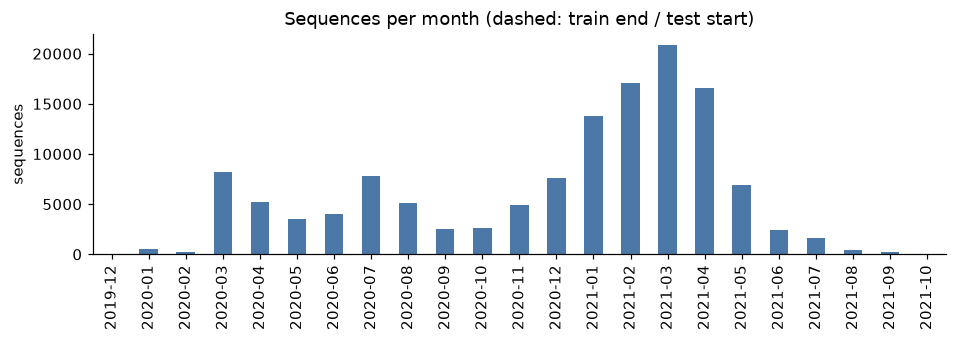

In [15]:
TRAIN_END  = pd.Timestamp("2021-02-28")
TEST_START = pd.Timestamp("2021-04-01")

fd = uniq.first_date
train_u = fd <= TRAIN_END
test_u  = fd >= TEST_START
print(f"唯一序列  train: {train_u.sum():,}   gap: {(~train_u & ~test_u).sum():,}   test: {test_u.sum():,}")

# 對「預測未來變異株」最重要的數字：測試期出現、但訓練期從未見過的序列
train_set = set(uniq.seq[train_u])
te_rows = df[df.date >= TEST_START]
seen = te_rows.seq.isin(train_set)
print(f"測試期原始序列中，序列在訓練期出現過: {seen.mean():.1%}；全新（訓練期從未見過）: {(~seen).mean():.1%}")

in_tr = df.date <= TRAIN_END; in_te = df.date >= TEST_START
print(f"原始序列  train: {in_tr.sum():,}   test: {in_te.sum():,}")

# 每月序列量
ax = df.groupby("month").size().plot(kind="bar", figsize=(10, 2.6), color="#4c78a8")
ax.set_ylabel("sequences"); ax.set_xlabel("")
for tag, ts, c in [("train end", TRAIN_END, "k"), ("test start", TEST_START, "r")]:
    ax.axvline(list(df.groupby("month").size().index.astype(str)).index(str(ts.to_period("M"))), color=c, ls="--", lw=1)
plt.title("Sequences per month (dashed: train end / test start)"); plt.show()

## 2. 資料探勘
### 2.1 突變頻率與時間趨勢

In [16]:
# 每個位點的「主要替代胺基酸」（以全資料中最常見的非參考殘基定義）
is_mut = (X_all != ref) & (X_all != 20)               # X 視為缺失
alt = np.zeros(L, dtype=np.uint8); alt_n = np.zeros(L, dtype=int)
for i in np.where(is_mut.any(0))[0]:
    cnt = np.bincount(X_all[is_mut[:, i], i], minlength=21)
    alt[i], alt_n[i] = cnt.argmax(), cnt.max()
mut_name = np.array([f"{AA21[ref[i]]}{i+1}{AA21[alt[i]]}" for i in range(L)])

months = sorted(df.month.unique())
mi = df.month.map({m: k for k, m in enumerate(months)}).values
n_m = np.bincount(mi)
def monthly_freq(match):                              # match: (n_seq, L) bool
    out = np.zeros((len(months), L))
    for k in range(len(months)):
        out[k] = match[mi == k].mean(0)
    return out
has_alt = alt_n > 0                                   # 沒有突變的位點 alt 預設為 0(A)，必須排除
F = monthly_freq((X_all == alt[None, :]) & has_alt[None, :])   # 月 × 位點（主要突變頻率）
F[n_m < 30] = np.nan                                  # 樣本太少的月份不畫
print("有突變的位點:", int((alt_n > 0).sum()), "  頻率 >5% 的突變:", int((np.nanmax(F, 0) > 0.05).sum()))

有突變的位點: 1021   頻率 >5% 的突變: 34


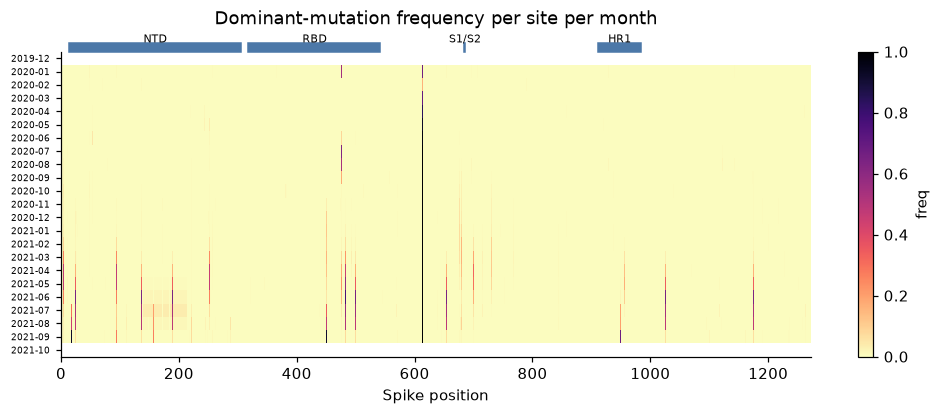

In [17]:
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(F, aspect="auto", cmap="magma_r", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(months))); ax.set_yticklabels([str(m) for m in months], fontsize=6)
ax.set_xlabel("Spike position"); ax.set_title("Dominant-mutation frequency per site per month", pad=18)
for name, lo, hi in [("NTD", 14, 305), ("RBD", 319, 541), ("S1/S2", 685, 686), ("HR1", 912, 984)]:
    ax.axvspan(lo - 1, hi, ymin=1.0, ymax=1.03, color="#4c78a8", clip_on=False)
    ax.text((lo + hi) / 2, -1.2, name, ha="center", fontsize=7)
plt.colorbar(im, label="freq"); plt.show()

,mut,slope_per_month,freq_end_of_train,max_freq_all
0,D614G,0.039105,0.997895,0.999402
1,L452R,0.008617,0.109071,0.913669
2,S13I,0.008351,0.105211,0.148235
3,W152C,0.008324,0.104684,0.147039
4,P681H,0.007809,0.149482,0.156606
5,Q677H,0.006091,0.073572,0.073572
6,L5F,0.004670,0.096380,0.468577
7,T732A,0.004469,0.094099,0.111158
8,T478K,0.002901,0.083338,0.917266
9,E484K,0.002648,0.067840,0.759674


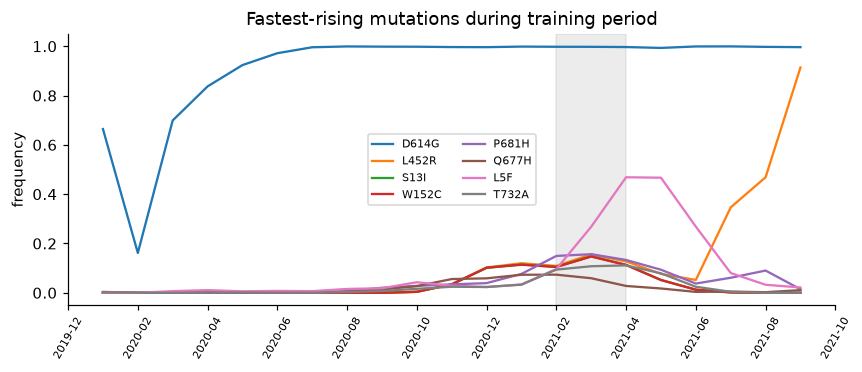

In [18]:
# 快速上升的突變：以「訓練期內」月頻率對時間做線性回歸，斜率最大者
tr_m = [k for k, m in enumerate(months) if m.end_time <= TRAIN_END + pd.Timedelta(days=1) and n_m[k] >= 30]
t = np.array(tr_m, float)
slope = np.array([np.polyfit(t, F[tr_m, i], 1)[0] if np.isfinite(F[tr_m, i]).all() else 0 for i in range(L)])
rise = pd.DataFrame({"mut": mut_name, "slope_per_month": slope,
                     "freq_end_of_train": F[tr_m[-1]],
                     "max_freq_all": np.nanmax(F, 0)}).iloc[np.argsort(-slope)[:15]]
display(rise.reset_index(drop=True))

top = list(rise.mut[:8])
fig, ax = plt.subplots(figsize=(9, 3.2))
x = [str(m) for m in months]
for nm in top:
    ax.plot(x, F[:, list(mut_name).index(nm)], label=nm, lw=1.5)
ax.axvspan(str(TRAIN_END.to_period("M")), str(TEST_START.to_period("M")), color="grey", alpha=.15)
ax.set_xticks(range(0, len(x), 2)); ax.set_xticklabels(x[::2], rotation=60, fontsize=7)
ax.set_ylabel("frequency"); ax.legend(ncol=2, fontsize=7); ax.set_title("Fastest-rising mutations during training period")
plt.show()

### 2.2 共現突變
把最常見的突變做成二元矩陣，計算兩兩**互資訊**（MI），看哪些突變一起出現（同一演化支）。

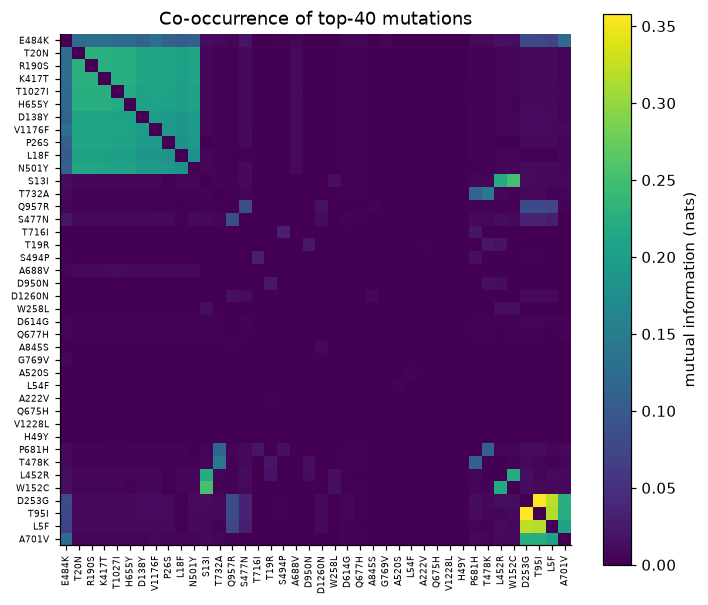

In [19]:
bin_u = (X_uniq == alt[None, :]) & has_alt[None, :]          # 唯一序列 × 位點
w = uniq["count"].values.astype(float)
freq = (bin_u * w[:, None]).sum(0) / w.sum()
sel = np.argsort(-freq)[:40]                                       # 頻率最高的 40 個突變
B = bin_u[:, sel].astype(float)

def weighted_mi(B, w):
    n = B.shape[1]; p1 = (B * w[:, None]).sum(0) / w.sum(); M = np.zeros((n, n))
    for a in range(n):
        for b in range(a, n):
            p11 = (B[:, a] * B[:, b] * w).sum() / w.sum()
            joint = np.array([[1 - p1[a] - p1[b] + p11, p1[b] - p11], [p1[a] - p11, p11]])
            pa = np.array([1 - p1[a], p1[a]]); pb = np.array([1 - p1[b], p1[b]])
            nz = joint > 1e-12
            M[a, b] = M[b, a] = (joint[nz] * np.log(joint[nz] / np.outer(pa, pb)[nz])).sum()
    return M
MI = weighted_mi(B, w); np.fill_diagonal(MI, 0)

from scipy.cluster.hierarchy import linkage, leaves_list
order = leaves_list(linkage(1 - MI / MI.max(), "average"))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(MI[np.ix_(order, order)], cmap="viridis")
ax.set_xticks(range(len(sel))); ax.set_xticklabels(mut_name[sel][order], rotation=90, fontsize=6)
ax.set_yticks(range(len(sel))); ax.set_yticklabels(mut_name[sel][order], fontsize=6)
plt.colorbar(im, label="mutual information (nats)"); ax.set_title("Co-occurrence of top-40 mutations"); plt.show()

### 2.3 序列聚類與潛在空間（PCA → 之後換成 VAE 的潛在空間）
這裡先用 one-hot 的 PCA當作線性基準；VAE 的潛在空間之後可以直接用同樣的作圖程式碼比較。
先用關鍵突變貼上粗略的 lineage 標籤。

In [20]:
def has(name):                    # 唯一序列是否帶有某突變（如 'N501Y'）
    pos = int(name[1:-1]) - 1; return X_uniq[:, pos] == AA.index(name[-1])

_has = {n: has(n) for n in ["D614G","N501Y","A570D","E484K","L452R","T478K"]}
def label_all():
    lab = np.full(len(uniq), "Wuhan-like (D614)", dtype=object)
    lab[_has["D614G"]] = "D614G only/other"
    lab[_has["E484K"]] = "E484K other"
    lab[_has["L452R"]] = "Epsilon-like (L452R)"
    lab[_has["N501Y"] & _has["E484K"]] = "Beta/Gamma-like (N501Y+E484K)"
    lab[_has["N501Y"] & _has["A570D"]] = "Alpha-like (N501Y+A570D)"
    lab[_has["L452R"] & _has["T478K"]] = "Delta-like (L452R+T478K)"
    return lab
uniq["group"] = label_all()
print(uniq.groupby("group")["count"].sum().sort_values(ascending=False).to_frame("n_sequences"))

                               n_sequences
group                                     
D614G only/other                     95570
E484K other                          12191
Epsilon-like (L452R)                 10491
Beta/Gamma-like (N501Y+E484K)         8411
Wuhan-like (D614)                     4374
Delta-like (L452R+T478K)              1033
Alpha-like (N501Y+A570D)               231


explained var (PC1-2): [0.104 0.089]   top-20 sum: 0.53


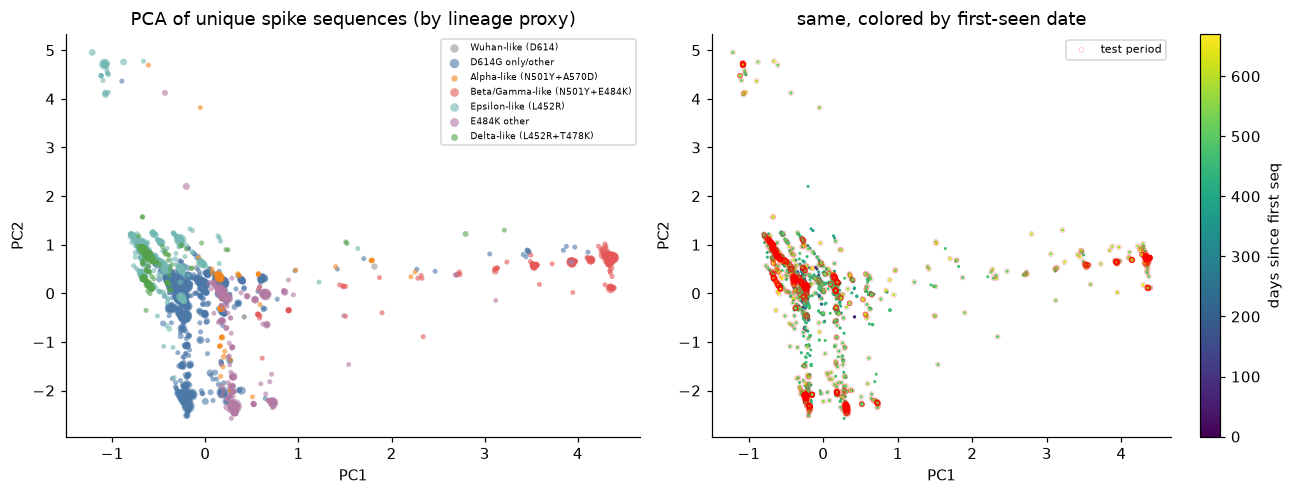

In [21]:
from sklearn.decomposition import PCA
# one-hot 必須先置中，否則 PC1 只是「平均向量」，沒有資訊
svd = PCA(n_components=20, svd_solver="randomized", random_state=0)
Z = svd.fit_transform(OH_uniq.toarray())              # 13.6k × 26.7k float32 ≈ 1.4 GB
print("explained var (PC1-2):", svd.explained_variance_ratio_[:2].round(3), "  top-20 sum:", svd.explained_variance_ratio_.sum().round(3))

palette = {"Wuhan-like (D614)":"#999999","D614G only/other":"#4c78a8","Alpha-like (N501Y+A570D)":"#f58518",
           "Beta/Gamma-like (N501Y+E484K)":"#e45756","Epsilon-like (L452R)":"#72b7b2","E484K other":"#b279a2",
           "Delta-like (L452R+T478K)":"#54a24b"}
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
for g, c in palette.items():
    s = uniq.group == g
    axs[0].scatter(Z[s, 0], Z[s, 1], s=4 + 10*np.log1p(uniq["count"][s]), c=c, alpha=.6, label=g, lw=0)
axs[0].legend(fontsize=6, markerscale=.8); axs[0].set_title("PCA of unique spike sequences (by lineage proxy)")
sc = axs[1].scatter(Z[:, 0], Z[:, 1], c=(uniq.first_date - uniq.first_date.min()).dt.days, cmap="viridis", s=4, lw=0)
plt.colorbar(sc, ax=axs[1], label="days since first seq"); axs[1].set_title("same, colored by first-seen date")
axs[1].scatter(Z[test_u, 0], Z[test_u, 1], s=10, facecolors="none", edgecolors="r", lw=.25, alpha=.5, label="test period")
axs[1].legend(fontsize=7)
for a in axs: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

group    Alpha-like (N501Y+A570D)  Beta/Gamma-like (N501Y+E484K)  \
cluster                                                            
0                               4                              0   
1                               0                             14   
2                               1                              0   
3                               0                            668   
4                               0                              0   
5                               2                              0   
6                               2                              0   
7                               0                              0   
8                               0                              0   
9                             103                              9   

group    D614G only/other  Delta-like (L452R+T478K)  E484K other  \
cluster                                                            
0                     109                      

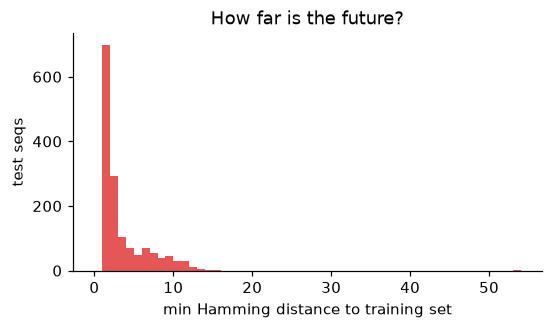

In [22]:
# Hamming 距離 + KMeans：看測試期的序列離訓練期最近的序列有多遠
# （這同時是之後評估「生成序列是否命中未來序列」的距離指標）
from sklearn.cluster import KMeans
km = KMeans(n_clusters=10, n_init=5, random_state=0).fit(Z)
uniq["cluster"] = km.labels_
print(pd.crosstab(uniq.cluster, uniq.group).loc[:, lambda d: d.sum() > 0])

def min_hamming(A, B, bs=256):                      # A:(n,L) B:(m,L) → 每列 A 到 B 的最小距離
    out = np.empty(len(A), dtype=np.int32)
    for i in range(0, len(A), bs):
        d = (A[i:i+bs, None, :] != B[None, :, :]).sum(-1); out[i:i+bs] = d.min(1)
    return out
rng = np.random.default_rng(0)
te_idx = np.where(test_u)[0]; te_idx = rng.choice(te_idx, min(1500, len(te_idx)), replace=False)
tr_X = X_uniq[train_u.values]
dmin = min_hamming(X_uniq[te_idx], tr_X)
print("測試期序列到訓練期最近序列的 Hamming 距離:",
      pd.Series(dmin).describe()[["mean","50%","max"]].round(2).to_dict())
plt.figure(figsize=(5.5, 2.8)); plt.hist(dmin, bins=range(0, dmin.max()+2), color="#e45756")
plt.xlabel("min Hamming distance to training set"); plt.ylabel("test seqs"); plt.title("How far is the future?"); plt.show()

### 2.4 系統發生樹（此 notebook 不執行）
IQ-TREE / UShER / Nextstrain 需要額外安裝且對 13 萬條序列很耗時。建議流程：
1. 輸出去重後的唯一序列（以及對應的核苷酸序列，若要建 DNA 樹）。
2. 對 `uniq` 的代表序列抽樣（例如每個 cluster 取 ≤200 條）。
3. `mafft` → `iqtree2 -m MFP` → 用 `ete3` / Auspice 檢視。

下面先把後續建模要用的中間產物存起來。

In [23]:
out = repo / "Research/FE/processed"; out.mkdir(exist_ok=True)
np.savez_compressed(out / "spike_uniq.npz", X=X_uniq, count=uniq["count"].values,
                    first_date=uniq.first_date.values.astype("datetime64[D]"),
                    train=train_u.values, test=test_u.values, ref=ref)
uniq.drop(columns="seq").to_csv(out / "spike_uniq_meta.csv", index=False)
print("saved to", out, [p.name for p in out.iterdir()])

saved to /home/cliffyang/Project/SARS-CoV-2-Quantum/Research/FE/processed ['spike_uniq_meta.csv', 'spike_uniq.npz']
